# CNN Lab - Cat vs Dog Classification
## Guide for Hands-on Session

This lab will guide you through building a Convolutional Neural Network (CNN) to classify images of cats and dogs. We'll go through each step with detailed explanations to help you understand how CNNs work.

### What You'll Learn:
- How to build a CNN architecture
- How to preprocess image data
- How to train a CNN model
- How to evaluate model performance

Let's start by importing the necessary libraries!


## Step 1: Import TensorFlow
TensorFlow is Google's open-source deep learning framework. We need it to build and train our CNN model.


In [1]:
import tensorflow

I0000 00:00:1787800937.196572   23125 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1787800937.197031   23125 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1787800937.237175   23125 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1787800938.336743   23125 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

## Step 2: Import Sequential Model
The Sequential model allows us to build our CNN layer by layer, one after another. It's like stacking building blocks!


In [2]:
from tensorflow.keras import Sequential

## Step 3: Import CNN Layers
We need different types of layers to build our CNN:
- **Input**: Defines the shape of our input images
- **Conv2D**: Convolutional layer that detects features like edges, shapes
- **MaxPool2D**: Reduces image size while keeping important features
- **Flatten**: Converts 2D image data to 1D for the final layers
- **Dense**: Fully connected layer for final classification


In [3]:
from tensorflow.keras.layers import Input, Conv2D, MaxPool2D, Flatten, Dense

## Step 4: Define Image Shape
We need to specify the size of our input images. All images will be resized to 64x64 pixels with 3 color channels (RGB).
- **64, 64**: Width and height in pixels
- **3**: Number of color channels (Red, Green, Blue)


In [4]:
target_shape = (128, 128, 3)

## Step 5: Create CNN Model
Now we'll create an empty Sequential model. Think of it as an empty container where we'll add our layers one by one.


In [5]:
cnn_model = Sequential()

## Step 6: Add Input Layer
The Input layer tells our model what size images to expect. It's like telling someone "I'm going to give you pictures that are 64x64 pixels with 3 colors."


In [6]:
cnn_model.add(Input(shape=target_shape))

## Step 7: Add Convolutional Layer
This is the heart of our CNN! The Conv2D layer detects features in images:
- **filters=32**: Creates 32 different feature detectors (like 32 different eyes looking for different patterns)
- **kernel_size=(3,3)**: Each detector looks at 3x3 pixel areas at a time
- **strides=(1,1)**: Moves 1 pixel at a time across the image
- **activation='relu'**: Makes the model non-linear (helps it learn complex patterns)


In [7]:
# Create the convolutional layer
conv_layer = Conv2D(filters = 64, 
                    kernel_size = (3,3), 
                    strides = (1, 1), 
                    kernel_initializer = 'glorot_uniform', #Strategy to init the filter
                    activation = "relu")

# Add it to our model
cnn_model.add(conv_layer)

E0000 00:00:1787800942.424685   23125 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## Step 8: Add Max Pooling Layer
Max pooling reduces the size of our feature maps while keeping the most important information:
- **pool_size=(2,2)**: Looks at 2x2 areas
- **strides=(2,2)**: Moves 2 pixels at a time
- This makes our model faster and helps prevent overfitting


In [8]:
# Create the max pooling layer
max_pooling_layer = MaxPool2D(pool_size=(2,2), strides=(2,2))

# Add it to our model
cnn_model.add(max_pooling_layer)

Add Conv layer-2

In [9]:
# Create the convolutional layer
conv_layer_2 = Conv2D(filters = 128, 
                    kernel_size = (3,3), 
                    strides = (1, 1), 
                    kernel_initializer = 'glorot_uniform', #Strategy to init the filter
                    activation = "relu")

# Add it to our model
cnn_model.add(conv_layer_2)

Add Pool layer 2

In [10]:
# Create the max pooling layer
max_pooling_layer_2 = MaxPool2D(pool_size=(2,2), strides=(2,2))

# Add it to our model
cnn_model.add(max_pooling_layer_2)

## Step 9: Add Flatten Layer
The flatten layer converts our 2D feature maps into a 1D vector. It's like taking a picture and turning it into a long list of numbers that our final layers can understand.


In [11]:
# Create the flatten layer
flatten_layer = Flatten()

# Add it to our model
cnn_model.add(flatten_layer)

## Step 10: Add Hidden Dense Layer
This is a fully connected layer that processes all the features we detected:
- **units=200**: Creates 200 neurons (like 200 brain cells working together)
- **activation='relu'**: Uses ReLU activation to help the model learn complex patterns
- This layer helps the model make better decisions about whether an image is a cat or dog


In [12]:
# Create the hidden dense layer
fc_layer = Dense(units = 400,
                 kernel_initializer="glorot_uniform",
                 bias_initializer="glorot_uniform",
                 activation="relu")

# Add it to our model
cnn_model.add(fc_layer)

## Step 11: Add Output Layer
This is our final layer that makes the prediction:
- **units=1**: Only one output (0 for cat, 1 for dog)
- **activation='sigmoid'**: Sigmoid function gives us a probability between 0 and 1
- If output > 0.5, we predict "dog", otherwise "cat"


In [13]:
# Create the output layer
output_layer = Dense(units = 1,
                     kernel_initializer="glorot_uniform",
                     bias_initializer="glorot_uniform",
                     activation="sigmoid")

# Add it to our model
cnn_model.add(output_layer)

## Step 12: View Model Summary
Let's see what our CNN architecture looks like! This shows us:
- How many layers we have
- The shape of data at each layer
- Total number of parameters (weights) the model needs to learn


In [14]:
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 400)            │    46,080,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           401 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,156,449 (176.07 MB)

 Trainable params: 46,156,449 (176.07 MB)

 Non-trainable params: 0 (0.00 B)

## Step 13: Visualize Model Architecture
Let's create a visual diagram of our CNN! This helps us understand how data flows through our model from input to output.


In [15]:
from tensorflow.keras.utils import plot_model

plot_model(cnn_model, 
           show_shapes=True, 
           show_layer_names=True,
           show_dtype=True,
           show_layer_activations=True, 
           expand_nested=True)

You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.


## Step 14: Compile the Model
Before we can train our model, we need to tell it:
- **Loss function**: How to measure mistakes (binary_crossentropy for yes/no questions)
- **Optimizer**: How to improve (Adam is a smart way to learn)
- **Metrics**: What to track during training (accuracy - how often we're right)


In [16]:
from tensorflow.keras.optimizers import SGD, Adam

# Create Adam optimizer with learning rate 0.001
adam = Adam(learning_rate=0.001)

# Compile the model
cnn_model.compile(loss="binary_crossentropy",  #formula to compute the error
                  optimizer=adam, #strategy to update the weights
                  metrics=["accuracy"])

## Step 15: Prepare Data Loading
Now we'll set up our data generators. These will:
- Load images from folders
- Resize them to 64x64 pixels
- Apply data augmentation (flip, rotate, zoom) to create more training examples
- Normalize pixel values to 0-1 range


In [17]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Training data generator with augmentation
train_gen = ImageDataGenerator(horizontal_flip=True,    # Flip images horizontally
                               rotation_range=0.2,      # Rotate up to 30 degrees
                               shear_range=0.15,         # Shear transformation -- rotation
                               zoom_range=0.01,         # Zoom in/out slightly
                               rescale=1/255.0)        # Normalize to 0-1 range

# Test data generator (no augmentation needed)
test_gen = ImageDataGenerator(rescale=1/255.0)

## Step 16: Load Training Data
We'll load our training images from the dataset folder. The generator will:
- Find all images in the training_set folder
- Automatically label them based on folder names (cats=0, dogs=1)
- Create batches of 64 images for training


In [18]:
target_shape[:2]

(128, 128)

In [19]:
# Load training data
train_data = train_gen.flow_from_directory(
    "dataset/training_set", 
    target_size = target_shape[:2],  # Resize to 64x64
    color_mode = "rgb",             # Use color images, gray -- grascale images
    class_mode = 'binary',          # Binary classification (cat=0, dog=1) ---"categorical" -- multiclass
    batch_size=64,               # Process 64 images at a time
    shuffle=True                 # Randomize order for better training
)

Found 7999 images belonging to 2 classes.


## Step 17: Load Test Data
Now we'll load our test images. These are used to check how well our model performs on new, unseen images.


In [20]:
# Load test data
test_data = test_gen.flow_from_directory(
    "dataset/test_set", 
    target_size=target_shape[:2],  # Resize to 64x64
    color_mode="rgb",             # Use color images
    class_mode='binary',          # Binary classification (cat=0, dog=1)
    batch_size=64,               # Process 64 images at a time
    shuffle=False                # Don't shuffle test data
)

Found 2000 images belonging to 2 classes.


## Step 18: Check Data Information
Let's see what our data looks like and understand the class labels.


In [21]:
# Check class labels
print("Class labels:", train_data.class_indices)
print("Number of training samples:", train_data.samples)
print("Number of test samples:", test_data.samples)

Class labels: {'cats': 0, 'dogs': 1}
Number of training samples: 7999
Number of test samples: 2000


## Step 19: Visualize Sample Images
Let's look at some sample images from our training data to make sure everything is loaded correctly.


In [22]:
train_data

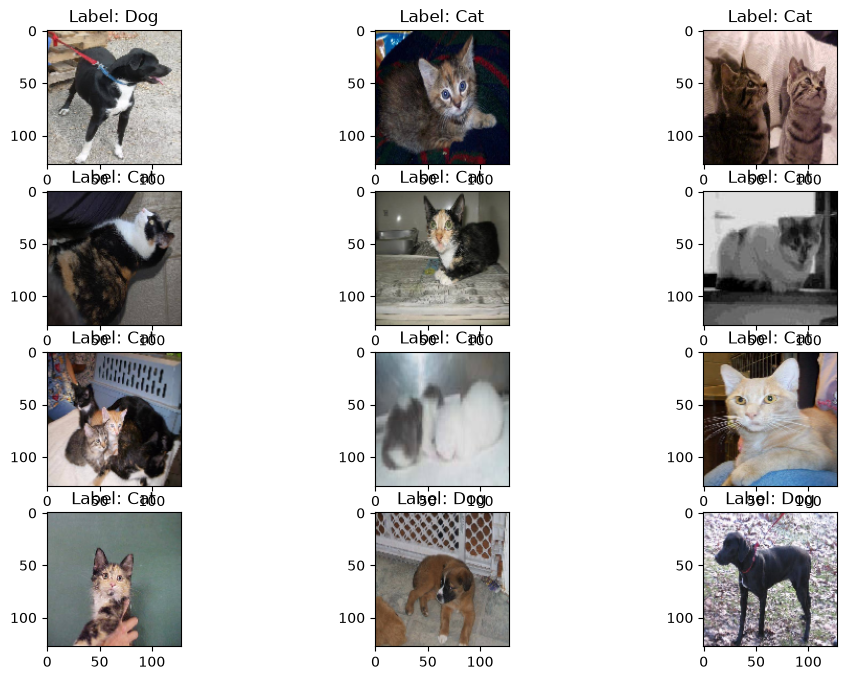

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
for idx,each_batch in enumerate(train_data,1):
    X, y = each_batch
    plt.subplot(4, 3, idx)
    plt.imshow(X[0])
    plt.title(f"Label: {'Dog' if y[0] == 1 else 'Cat'}")
    
    if idx >= 12:
        break

## Step 20: Train the Model
Now comes the exciting part - training our CNN! This is where our model learns to distinguish between cats and dogs:
- **epochs=20**: The model will see all training images 20 times
- Each epoch helps the model get better at recognizing patterns
- Watch the accuracy improve as training progresses!


In [25]:

history = cnn_model.fit(train_data, epochs=20)

Epoch 1/20


I0000 00:00:1787801099.712707   23125 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


125/125 ━━━━━━━━━━━━━━━━━━━━ 107s 846ms/step - accuracy: 0.5944 - loss: 0.7894
Epoch 2/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 116s 931ms/step - accuracy: 0.7038 - loss: 0.5647
Epoch 3/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 117s 933ms/step - accuracy: 0.7492 - loss: 0.5037
Epoch 4/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 119s 950ms/step - accuracy: 0.7911 - loss: 0.4400
Epoch 5/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 123s 982ms/step - accuracy: 0.8289 - loss: 0.3810
Epoch 6/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 116s 928ms/step - accuracy: 0.8577 - loss: 0.3257
Epoch 7/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 115s 919ms/step - accuracy: 0.8940 - loss: 0.2612
Epoch 8/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 104s 829ms/step - accuracy: 0.9222 - loss: 0.1926
Epoch 9/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 104s 828ms/step - accuracy: 0.9387 - loss: 0.1541
Epoch 10/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 104s 831ms/step - accuracy: 0.9591 - loss: 0.1117
Epoch 11/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 137s 795ms/step - accuracy: 0.9702 - loss: 0.0909
Epoch 12/20
125/125

In [27]:
history

In [30]:
history.history

{'accuracy': [0.4930616319179535,
  0.5535691976547241,
  0.6487060785293579,
  0.7008376121520996,
  0.7347168326377869,
  0.7449681162834167,
  0.7697212100028992,
  0.7760969996452332,
  0.7917239665985107,
  0.7987248301506042,
  0.8198524713516235,
  0.8216027021408081,
  0.8361045122146606,
  0.8451056480407715,
  0.8566070795059204,
  0.852106511592865,
  0.8701087832450867,
  0.8739842772483826,
  0.8856106996536255,
  0.8941117525100708],
 'loss': [0.867264449596405,
  0.6827473640441895,
  0.6238852143287659,
  0.5757505297660828,
  0.5405817031860352,
  0.5210891366004944,
  0.4851227104663849,
  0.46948644518852234,
  0.44584256410598755,
  0.4344000816345215,
  0.4080187976360321,
  0.39660224318504333,
  0.36925867199897766,
  0.35367265343666077,
  0.3348414897918701,
  0.3388702869415283,
  0.30927425622940063,
  0.29535624384880066,
  0.2782137095928192,
  0.2611585259437561]}

In [31]:
accuracy_list = history.history["accuracy"]
epochs = list(range(1,len(accuracy_list)+1))

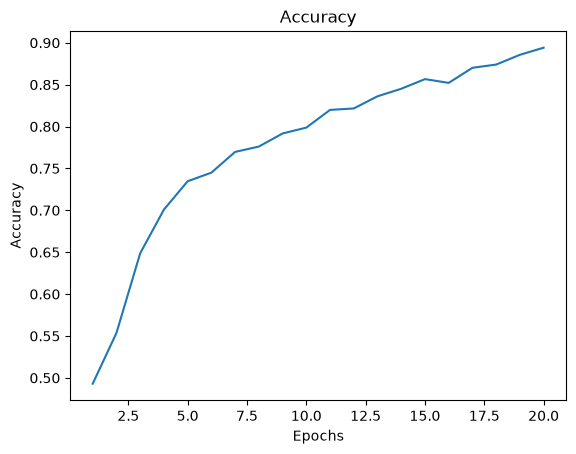

In [33]:
plt.plot(epochs, accuracy_list)
plt.title("Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.show()

In [35]:
loss_list = history.history["loss"]

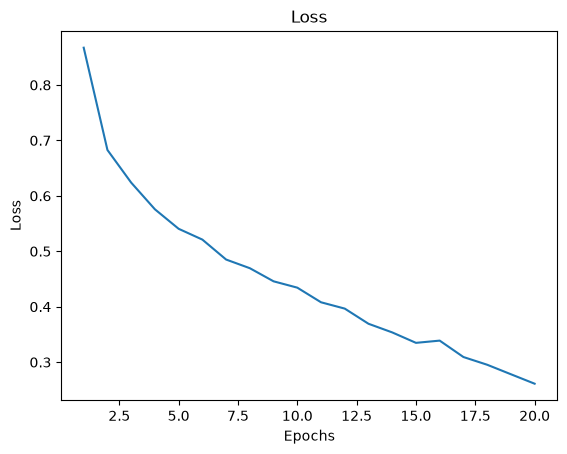

In [36]:
plt.plot(epochs, loss_list)
plt.title("Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()

## Step 21: Make Predictions on Test Data
Now let's test our trained model on images it has never seen before. This tells us how well our model will work in real life.


In [38]:
2000/64

31.25

In [39]:
y_pred = cnn_model.predict(test_data)

32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 63ms/step


## Step 22: Get True Labels
We need to get the actual labels (ground truth) for our test images to compare with our predictions.


In [40]:
# Get the true labels for test data
y_test = test_data.classes

In [41]:
y_test

array([0, 0, 0, ..., 1, 1, 1], shape=(2000,), dtype=int32)

## Step 23: Convert Predictions to Binary
Our model outputs probabilities (0-1). We need to convert these to binary predictions:
- If probability > 0.5, predict "Dog" (1)
- If probability ≤ 0.5, predict "Cat" (0)


In [42]:
y_pred

array([[0.45908248],
       [0.9042983 ],
       [0.01819254],
       ...,
       [0.04293272],
       [0.17226197],
       [0.9843462 ]], shape=(2000, 1), dtype=float32)

In [44]:
# Convert probabilities to binary predictions
y_pred = y_pred > 0.5
y_pred = y_pred.astype("int")

In [45]:
y_pred

array([[0],
       [1],
       [0],
       ...,
       [0],
       [0],
       [1]], shape=(2000, 1))

## Step 24: Calculate Model Performance
Let's see how well our model performed! We'll calculate accuracy and get a detailed classification report.


In [46]:
from sklearn.metrics import accuracy_score, classification_report

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Test Data Accuracy: {accuracy:.3f}")

# Print detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Test Data Accuracy: 0.746

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.78      0.75      1000
           1       0.77      0.71      0.74      1000

    accuracy                           0.75      2000
   macro avg       0.75      0.75      0.75      2000
weighted avg       0.75      0.75      0.75      2000



## Step 25: Save the Trained Model
Great job! Your model is trained and working. Let's save it so you can use it later without retraining.


In [47]:
# Save the trained model
cnn_model.save("cnn_cat_dog_classifier.keras")
print("Model saved successfully as 'cnn_cat_dog_classifier.keras'")

Model saved successfully as 'cnn_cat_dog_classifier.keras'


## Congratulations! 🎉

You've successfully built and trained a CNN to classify cats and dogs! Here's what you accomplished:

### What You Built:
1. **CNN Architecture**: A 5-layer neural network with convolutional, pooling, and dense layers
2. **Data Pipeline**: Automated image loading, preprocessing, and augmentation
3. **Training Process**: 20 epochs of learning to recognize cat and dog features
4. **Model Evaluation**: Tested performance on unseen images

### Key Concepts You Learned:
- **Convolutional Layers**: Detect features like edges, shapes, and patterns
- **Pooling Layers**: Reduce image size while keeping important information
- **Dense Layers**: Make final classification decisions
- **Data Augmentation**: Create more training examples by transforming images
- **Binary Classification**: Distinguish between two classes (cats vs dogs)

### Next Steps:
- Try different architectures (more layers, different filter sizes)
- Experiment with different hyperparameters (learning rate, batch size)
- Test on your own images
- Try classifying other animals or objects

Keep exploring and happy coding! 🚀
